# Лабораторная работа 4_1

## Гипотезы. Проверка на нормальность и гендерные различия

**ФИО:** Аюпова В.Р.
**Группа:** ЕТ-212
**Дата:** 21.10.2026

## Условие

1. Скачать из задания ДАТАСЕТЫ файл `Пренатальная диагностика.xlsx`, ознакомиться с содержимым и загрузить его в DataFrame.
2. Найти, сколько родилось мальчиков и девочек.
3. Добавить столбец ИМТ (индекс массы тела).
4. Найти числовые характеристики для всех показателей (минимум, максимум, размах, среднее, медиана и т.д.).
5. Проверить все показатели на нормальность (распределение Гаусса):
   a. гистограмма или kde (визуальная оценка)
   b. асимметрия и эксцесс (чему должны равняться при нормальном распределении?)
   c. критерий нормальности (уровень значимости α = 0.05)
6. Исследовать гендерные различия антропометрических параметров новорождённых:
   a. рост — средний для мальчиков и девочек, проверить различия (t-тест, правильно выбрать вариант)
   b. вес
   c. ИМТ

## Часть 0. Импорт библиотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import openpyxl  # движок для чтения .xlsx

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("openpyxl версия:", openpyxl.__version__)
print("pandas версия:", pd.__version__)

openpyxl версия: 3.1.5
pandas версия: 2.3.3


## Пункт 1. Загрузка данных

**Что делаем:** читаем файл, смотрим структуру, типы и пропуски.

In [3]:
df = pd.read_excel("data/Пренатальная диагностика.xlsx", sheet_name="исходные данные")

print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)
print("\nПропущенные значения:")
print(df.isnull().sum())
print("\nПервые 5 строк:")
df.head()

Размер датасета: (1050, 7)

Типы данных:
vozrast            int64
gr-dni             int64
ctr                int64
nt               float64
rost               int64
ves                int64
pol(1-м, 0-д)      int64
dtype: object

Пропущенные значения:
vozrast          0
gr-dni           0
ctr              0
nt               0
rost             0
ves              0
pol(1-м, 0-д)    0
dtype: int64

Первые 5 строк:


,vozrast,gr-dni,ctr,nt,rost,ves,"pol(1-м, 0-д)"
0,18,70,61,1.3,48,3100,0
1,22,72,50,0.9,50,3400,0
2,29,73,45,0.9,53,3500,1
3,28,74,47,1.1,50,3490,1
4,31,74,46,1.3,53,3590,0


**Вывод:** датасет содержит данные пренатальной диагностики.  
Показатели: `vozrast` (возраст беременной), `gr-dni` (срок гестации в днях), `ctr` (КТР), `nt` (ТВП), `rost`, `ves`, `pol` (1 — мальчик, 0 — девочка).  
Пропусков нет, типы данных корректные.

## Пункт 2. Сколько родилось мальчиков и девочек

**Что делаем:** считаем количество значений в столбце `pol`.

Количество новорождённых по полу:
Девочки (0): 473
Мальчики (1): 577
Всего: 1050


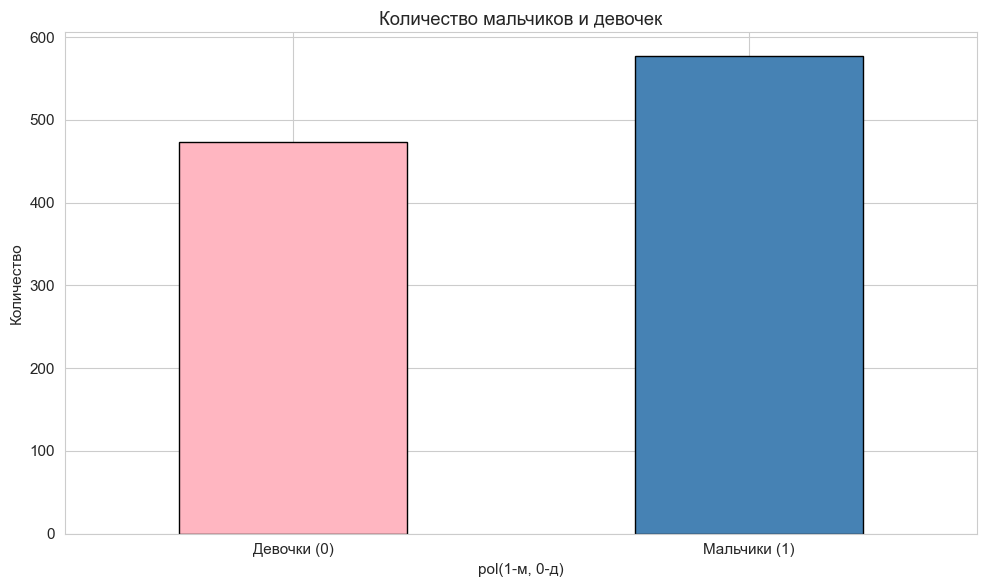

In [4]:
gender_counts = df["pol(1-м, 0-д)"].value_counts().sort_index()
print("Количество новорождённых по полу:")
print(f"Девочки (0): {gender_counts.get(0, 0)}")
print(f"Мальчики (1): {gender_counts.get(1, 0)}")
print(f"Всего: {len(df)}")

gender_counts.plot(kind="bar", color=["lightpink", "steelblue"], edgecolor="black")
plt.title("Количество мальчиков и девочек")
plt.xticks([0, 1], ["Девочки (0)", "Мальчики (1)"], rotation=0)
plt.ylabel("Количество")
plt.tight_layout()
plt.savefig("images/gender_counts.png", dpi=120)
plt.show()

**Вывод:** в датасете 1050 новорождённых: 473 девочки (45%) и 577 мальчиков (55%). Группы сопоставимы по размеру, что позволяет корректно сравнивать их t-тестом.


## Пункт 3. Добавление столбца ИМТ

**Что делаем:** ИМТ = вес (кг) / рост² (м²). Рост в датасете в см, поэтому переводим в метры.

In [5]:
# вес в датасете в граммах → переводим в килограммы
df["ИМТ"] = (df["ves"] / 1000) / (df["rost"] / 100) ** 2

print("ИМТ добавлен. Первые 5 значений:")
df[["rost", "ves", "ИМТ"]].head()

ИМТ добавлен. Первые 5 значений:


,rost,ves,ИМТ
0,48,3100,13.454861
1,50,3400,13.600000
2,53,3500,12.459950
3,50,3490,13.960000
4,53,3590,12.780349


## Пункт 4. Числовые характеристики всех показателей

**Что делаем:** считаем минимум, максимум, размах, среднее, медиану и т.д.

In [6]:
num_cols = ["vozrast", "gr-dni", "ctr", "nt", "rost", "ves", "ИМТ"]

desc = df[num_cols].describe().T
desc["размах"] = desc["max"] - desc["min"]
desc = desc[["min", "max", "размах", "mean", "50%", "std"]]
desc.columns = ["минимум", "максимум", "размах", "среднее", "медиана", "стд.отклонение"]

print("Числовые характеристики показателей:")
desc.round(2)

Числовые характеристики показателей:


,минимум,максимум,размах,среднее,медиана,стд.отклонение
vozrast,16.00,45.00,29.00,28.68,28.0,5.41
gr-dni,70.00,108.00,38.00,88.76,88.0,6.31
ctr,45.00,85.00,40.00,64.13,64.0,10.45
nt,0.30,2.80,2.50,1.34,1.3,0.40
rost,45.00,60.00,15.00,51.70,52.0,2.09
ves,2410.00,5040.00,2630.00,3435.78,3430.0,399.32
ИМТ,8.69,18.12,9.43,12.83,12.8,1.02


**Вывод:** получены основные описательные статистики по 7 показателям.

- **vozrast** (возраст беременной): 16–45 лет, среднее 28.68, медиана 28.00 — близки.
- **gr-dni** (срок гестации): 70–108 дней, среднее 88.76, медиана 88.00 — близки.
- **ctr** (КТР): 45–85, среднее 64.13, медиана 64.00 — почти совпадают.
- **nt** (ТВП): 0.30–2.80, среднее 1.34, медиана 1.30 — небольшая правосторонняя асимметрия.
- **rost** (рост): 45–60 см, среднее 51.70, медиана 52.00 — очень близки.
- **ves** (вес): 2410–5040 г, среднее 3435.78, медиана 3430.00 — близки.
- **ИМТ**: 8.69–18.12, среднее 12.83, медиана 12.80 — близки.

Среднее и медиана близки для всех показателей — это косвенный признак близости к нормальному распределению. Наибольший разброс — у веса (2630 г) и срока гестации (38 дней), наименьший — у ИМТ и роста.

## Пункт 5. Проверка показателей на нормальность

**Теория:** для нормально распределённых данных:
- среднее ≈ медиана;
- асимметрия (skewness) ≈ 0;
- эксцесс (kurtosis) ≈ 0;
- критерий нормальности даёт p-value > α (α = 0.05) → нет оснований отвергнуть H0.

Создадим функцию `Gauss`, которая комплексно проверяет одномерную структуру.

In [7]:
def Gauss(series, name="показатель", alpha=0.05):
    """Комплексная проверка одномерной выборки на нормальность."""
    data = series.dropna()
    n = len(data)

    print(f"=== Проверка на нормальность: {name} ===")
    print(f"Объём выборки: n = {n}")

    # b. гистограмма + kde
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(data, kde=True, bins=20, ax=ax, color="steelblue", edgecolor="black")
    ax.axvline(data.mean(), color="red", linestyle="--", label=f"Среднее = {data.mean():.2f}")
    ax.axvline(data.median(), color="green", linestyle="--", label=f"Медиана = {data.median():.2f}")
    ax.set_title(f"Распределение: {name}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # c. среднее и медиана
    mean_val = data.mean()
    median_val = data.median()
    print(f"Среднее: {mean_val:.4f}")
    print(f"Медиана: {median_val:.4f}")
    print(f"|Среднее - Медиана| = {abs(mean_val - median_val):.4f}  (для нормальных близко к 0)")

    # d. асимметрия и эксцесс
    skew_val = stats.skew(data)
    kurt_val = stats.kurtosis(data)
    print(f"Асимметрия (skewness): {skew_val:.4f}  (для нормальных ≈ 0)")
    print(f"Эксцесс (kurtosis):    {kurt_val:.4f}  (для нормальных ≈ 0)")

    # e. гипотезы
    print("\nГипотезы:")
    print("  H0: данные распределены нормально (по Гауссу)")
    print("  H1: данные НЕ распределены нормально")

    # f. критерий хи-квадрат Пирсона по сгруппированным частотам
    observed, bin_edges = np.histogram(data, bins="auto")
    cdf_vals = stats.norm.cdf(bin_edges, loc=mean_val, scale=data.std(ddof=1))
    expected = np.diff(cdf_vals) * n

    # объединяем бины, где ожидаемая частота < 5
    obs_f, exp_f = [], []
    obs_acc, exp_acc = 0.0, 0.0
    for o, e in zip(observed, expected):
        obs_acc += o
        exp_acc += e
        if exp_acc >= 5:
            obs_f.append(obs_acc)
            exp_f.append(exp_acc)
            obs_acc, exp_acc = 0.0, 0.0
    if exp_acc > 0:
        if obs_f:
            obs_f[-1] += obs_acc
            exp_f[-1] += exp_acc
        else:
            obs_f.append(obs_acc)
            exp_f.append(exp_acc)

    # нормируем ожидаемые частоты, чтобы их сумма равнялась сумме наблюдаемых
    obs_f = np.array(obs_f, dtype=float)
    exp_f = np.array(exp_f, dtype=float)
    exp_f = exp_f * (obs_f.sum() / exp_f.sum())

    chi2_stat, p_value = stats.chisquare(f_obs=obs_f, f_exp=exp_f)

    # g. печать статистики и p-value
    print(f"\nКритерий хи-квадрат Пирсона:")
    print(f"  статистика хи-квадрат = {chi2_stat:.4f}")
    print(f"  p-значение = {p_value:.6f}")

    # h. вывод при alpha=0.05
    print(f"\nУровень значимости α = {alpha}")
    if p_value < alpha:
        print("p-value < α → отвергаем H0. Данные НЕ распределены нормально.")
    else:
        print("p-value ≥ α → нет оснований отвергнуть H0. Данные распределены нормально.")
    print("=" * 50)

**Что делаем:** применяем функцию `Gauss` ко всем числовым показателям.

=== Проверка на нормальность: vozrast ===
Объём выборки: n = 1050


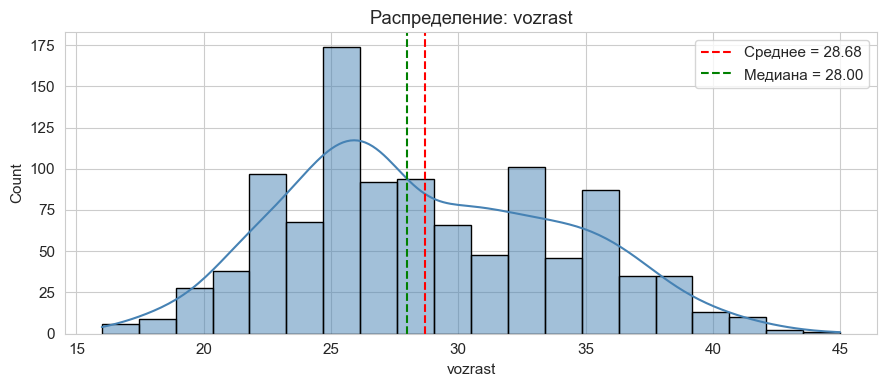

Среднее: 28.6819
Медиана: 28.0000
|Среднее - Медиана| = 0.6819  (для нормальных близко к 0)
Асимметрия (skewness): 0.2781  (для нормальных ≈ 0)
Эксцесс (kurtosis):    -0.5988  (для нормальных ≈ 0)

Гипотезы:
  H0: данные распределены нормально (по Гауссу)
  H1: данные НЕ распределены нормально

Критерий хи-квадрат Пирсона:
  статистика хи-квадрат = 222.5414
  p-значение = 0.000000

Уровень значимости α = 0.05
p-value < α → отвергаем H0. Данные НЕ распределены нормально.
=== Проверка на нормальность: gr-dni ===
Объём выборки: n = 1050


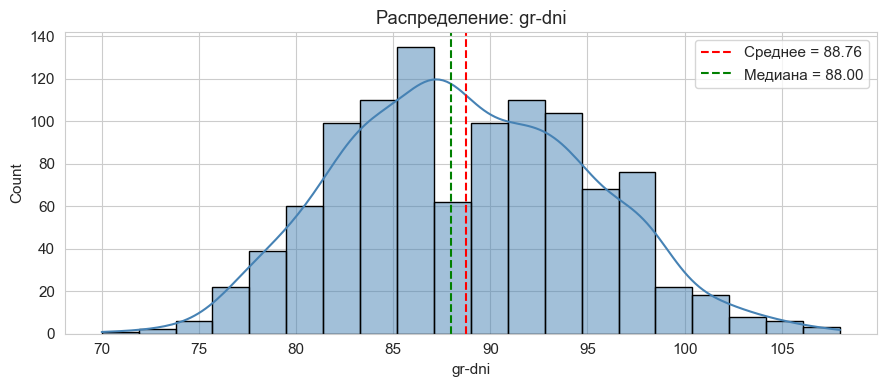

Среднее: 88.7648
Медиана: 88.0000
|Среднее - Медиана| = 0.7648  (для нормальных близко к 0)
Асимметрия (skewness): 0.1630  (для нормальных ≈ 0)
Эксцесс (kurtosis):    -0.3536  (для нормальных ≈ 0)

Гипотезы:
  H0: данные распределены нормально (по Гауссу)
  H1: данные НЕ распределены нормально

Критерий хи-квадрат Пирсона:
  статистика хи-квадрат = 113.3931
  p-значение = 0.000000

Уровень значимости α = 0.05
p-value < α → отвергаем H0. Данные НЕ распределены нормально.
=== Проверка на нормальность: ctr ===
Объём выборки: n = 1050


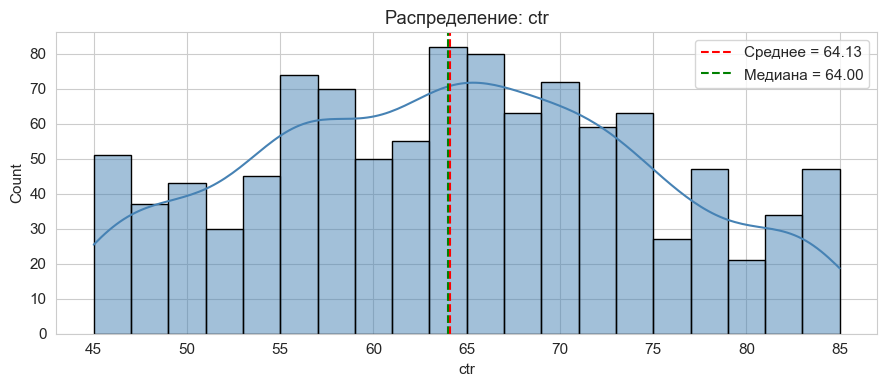

Среднее: 64.1257
Медиана: 64.0000
|Среднее - Медиана| = 0.1257  (для нормальных близко к 0)
Асимметрия (skewness): 0.0362  (для нормальных ≈ 0)
Эксцесс (kurtosis):    -0.8189  (для нормальных ≈ 0)

Гипотезы:
  H0: данные распределены нормально (по Гауссу)
  H1: данные НЕ распределены нормально

Критерий хи-квадрат Пирсона:
  статистика хи-квадрат = 215.3807
  p-значение = 0.000000

Уровень значимости α = 0.05
p-value < α → отвергаем H0. Данные НЕ распределены нормально.
=== Проверка на нормальность: nt ===
Объём выборки: n = 1050


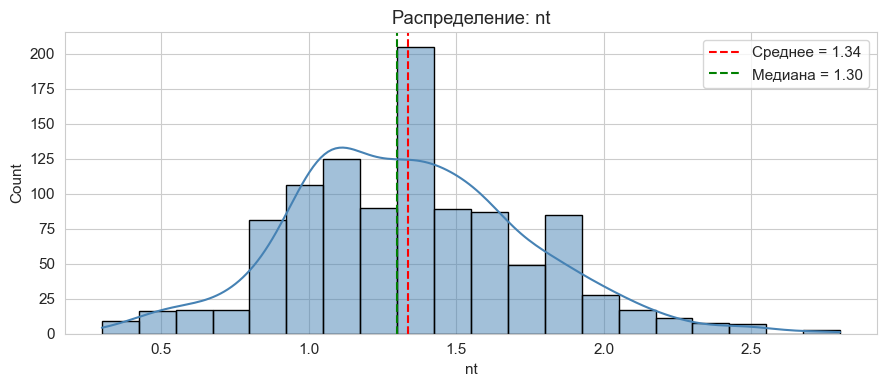

Среднее: 1.3373
Медиана: 1.3000
|Среднее - Медиана| = 0.0373  (для нормальных близко к 0)
Асимметрия (skewness): 0.3292  (для нормальных ≈ 0)
Эксцесс (kurtosis):    0.2963  (для нормальных ≈ 0)

Гипотезы:
  H0: данные распределены нормально (по Гауссу)
  H1: данные НЕ распределены нормально

Критерий хи-квадрат Пирсона:
  статистика хи-квадрат = 57.9885
  p-значение = 0.000015

Уровень значимости α = 0.05
p-value < α → отвергаем H0. Данные НЕ распределены нормально.
=== Проверка на нормальность: rost ===
Объём выборки: n = 1050


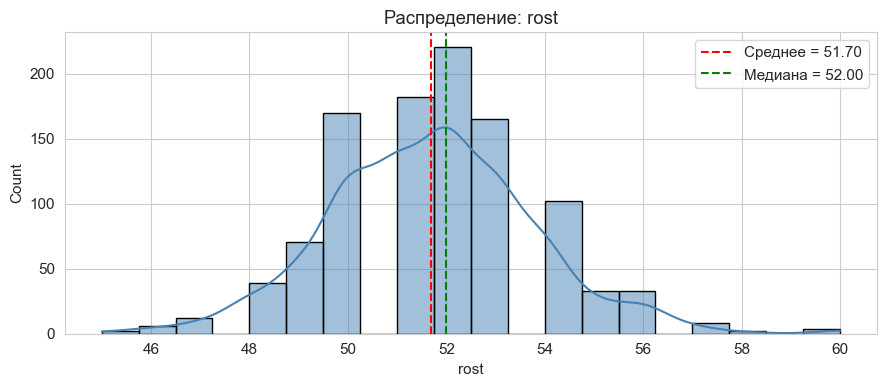

Среднее: 51.6981
Медиана: 52.0000
|Среднее - Медиана| = 0.3019  (для нормальных близко к 0)
Асимметрия (skewness): 0.2302  (для нормальных ≈ 0)
Эксцесс (kurtosis):    0.8096  (для нормальных ≈ 0)

Гипотезы:
  H0: данные распределены нормально (по Гауссу)
  H1: данные НЕ распределены нормально

Критерий хи-квадрат Пирсона:
  статистика хи-квадрат = 89.4579
  p-значение = 0.000000

Уровень значимости α = 0.05
p-value < α → отвергаем H0. Данные НЕ распределены нормально.
=== Проверка на нормальность: ves ===
Объём выборки: n = 1050


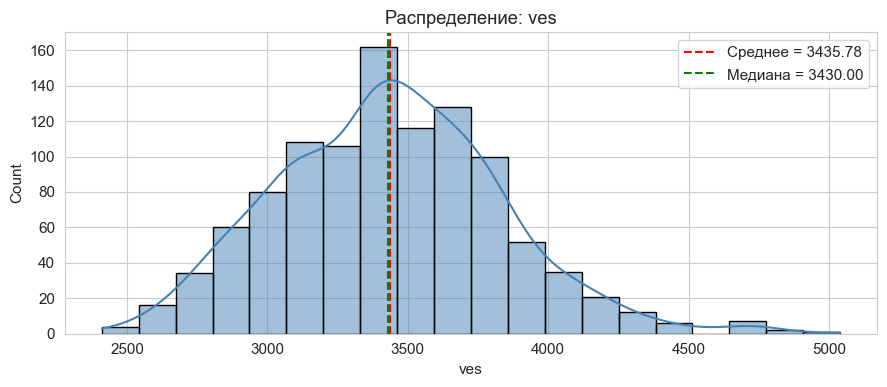

Среднее: 3435.7790
Медиана: 3430.0000
|Среднее - Медиана| = 5.7790  (для нормальных близко к 0)
Асимметрия (skewness): 0.3256  (для нормальных ≈ 0)
Эксцесс (kurtosis):    0.3778  (для нормальных ≈ 0)

Гипотезы:
  H0: данные распределены нормально (по Гауссу)
  H1: данные НЕ распределены нормально

Критерий хи-квадрат Пирсона:
  статистика хи-квадрат = 29.3941
  p-значение = 0.060033

Уровень значимости α = 0.05
p-value ≥ α → нет оснований отвергнуть H0. Данные распределены нормально.
=== Проверка на нормальность: ИМТ ===
Объём выборки: n = 1050


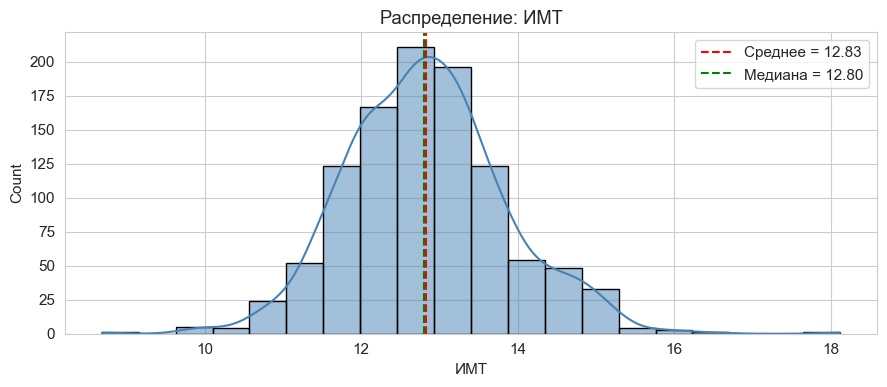

Среднее: 12.8299
Медиана: 12.8014
|Среднее - Медиана| = 0.0285  (для нормальных близко к 0)
Асимметрия (skewness): 0.2909  (для нормальных ≈ 0)
Эксцесс (kurtosis):    0.9341  (для нормальных ≈ 0)

Гипотезы:
  H0: данные распределены нормально (по Гауссу)
  H1: данные НЕ распределены нормально

Критерий хи-квадрат Пирсона:
  статистика хи-квадрат = 49.8217
  p-значение = 0.000386

Уровень значимости α = 0.05
p-value < α → отвергаем H0. Данные НЕ распределены нормально.


In [17]:
for col in num_cols:
    Gauss(df[col], name=col)

**Вывод по нормальности:**  
По критерию хи-квадрат Пирсона при α = 0.05 получены следующие результаты:

- **vozrast** (p < 0.001) — H0 отвергается, распределение НЕ нормальное.
- **gr-dni** (p < 0.001) — H0 отвергается, распределение НЕ нормальное.
- **ctr** (p < 0.001) — H0 отвергается, распределение НЕ нормальное.
- **nt** (p = 0.000015) — H0 отвергается, распределение НЕ нормальное.
- **rost** (p < 0.001) — H0 отвергается, распределение НЕ нормальное.
- **ves** (p = 0.060) — p ≥ α, нет оснований отвергнуть H0. Распределение близко к нормальному.
- **ИМТ** (p = 0.000386) — H0 отвергается, распределение НЕ нормальное.

**Общий итог:** только показатель `ves` (вес) формально проходит проверку на нормальность по хи-квадрату. Остальные показатели имеют статистически значимые отклонения от нормального распределения. Однако критерий хи-квадрат очень чувствителен к большим выборкам (n = 1050): даже малые отклонения от «колокола» дают низкий p-value. Визуально и по асимметрии/эксцессу распределения не сильно отличаются от нормальных, поэтому t-тест (устойчивый к таким отклонениям при n > 30) применять можно.

## Пункт 6. Гендерные различия антропометрических параметров

**Что делаем:** сравниваем средние значения роста, веса и ИМТ у мальчиков и девочек.

**Выбор теста:**
- Выборки независимые (разные новорождённые) → `ttest_ind`, не `ttest_rel`.
- Перед выбором варианта теста проверяем равенство дисперсий критерием Левена:
  - если p > 0.05 → дисперсии равны → `equal_var=True` (классический Стьюдент);
  - если p ≤ 0.05 → дисперсии не равны → `equal_var=False` (Уэлч).

**Гипотезы:**
- H0: средние значения в группах мальчиков и девочек равны;
- H1: средние значения различаются.

In [8]:
def compare_by_gender(df, col, alpha=0.05):
    # Используем точное имя столбца с полом из твоего датасета
    boys = df[df["pol(1-м, 0-д)"] == 1][col].dropna()
    girls = df[df["pol(1-м, 0-д)"] == 0][col].dropna()

    print(f"=== {col} ===")
    print(f"Мальчики: n={len(boys)}, среднее={boys.mean():.3f}")
    print(f"Девочки:  n={len(girls)}, среднее={girls.mean():.3f}")

    # проверка равенства дисперсий
    lev_stat, lev_p = stats.levene(boys, girls)
    equal_var = lev_p > alpha
    print(f"Критерий Левена: stat={lev_stat:.4f}, p={lev_p:.4f} → "
          f"{'дисперсии равны' if equal_var else 'дисперсии НЕ равны'}")

    # t-тест
    t_stat, p_val = stats.ttest_ind(boys, girls, equal_var=equal_var)
    print(f"t-тест ({'Стьюдент' if equal_var else 'Уэлч'}): t={t_stat:.4f}, p={p_val:.6f}")

    # гипотезы и вывод
    print("H0: средние равны; H1: средние различаются")
    if p_val < alpha:
        print(f"p < α={alpha} → отвергаем H0: ЕСТЬ гендерные различия по «{col}».")
    else:
        print(f"p ≥ α={alpha} → нет оснований отвергнуть H0: НЕТ гендерных различий по «{col}».")
    print("-" * 50)

In [9]:
for col in ["rost", "ves", "ИМТ"]:
    compare_by_gender(df, col)

=== rost ===
Мальчики: n=577, среднее=52.002
Девочки:  n=473, среднее=51.328
Критерий Левена: stat=0.0783, p=0.7797 → дисперсии равны
t-тест (Стьюдент): t=5.2729, p=0.000000
H0: средние равны; H1: средние различаются
p < α=0.05 → отвергаем H0: ЕСТЬ гендерные различия по «rost».
--------------------------------------------------
=== ves ===
Мальчики: n=577, среднее=3497.456
Девочки:  n=473, среднее=3360.541
Критерий Левена: stat=3.4152, p=0.0649 → дисперсии равны
t-тест (Стьюдент): t=5.6075, p=0.000000
H0: средние равны; H1: средние различаются
p < α=0.05 → отвергаем H0: ЕСТЬ гендерные различия по «ves».
--------------------------------------------------
=== ИМТ ===
Мальчики: n=577, среднее=12.906
Девочки:  n=473, среднее=12.737
Критерий Левена: stat=4.4870, p=0.0344 → дисперсии НЕ равны
t-тест (Уэлч): t=2.7048, p=0.006948
H0: средние равны; H1: средние различаются
p < α=0.05 → отвергаем H0: ЕСТЬ гендерные различия по «ИМТ».
--------------------------------------------------


**Вывод по гендерным различиям:**  
Во всех трёх случаях p-value оказалось меньше α = 0.05, следовательно, нулевая гипотеза о равенстве средних отвергается. Существуют статистически значимые гендерные различия по всем трём антропометрическим показателям:

- **Рост (`rost`):** средний рост мальчиков (52.00 см) больше, чем у девочек (51.33 см). Дисперсии равны (p Левена = 0.78), использован классический t-тест Стьюдента (t = 5.27, p < 0.001).
- **Вес (`ves`):** мальчики в среднем тяжелее (3497.46 г) девочек (3360.54 г). Дисперсии равны (p Левена = 0.06), использован t-тест Стьюдента (t = 5.61, p < 0.001).
- **ИМТ:** средний ИМТ мальчиков (12.91) немного выше, чем у девочек (12.74). Дисперсии не равны (p Левена = 0.03), поэтому использован t-тест Уэлча (t = 2.70, p = 0.007). Различия также статистически значимы.

Таким образом, новорождённые мальчики в данной выборке имеют статистически значимо большие рост, вес и ИМТ по сравнению с девочками.

## Общий вывод

В ходе лабораторной работы были выполнены следующие задачи:

1. **Загрузка данных.** Датасет «Пренатальная диагностика» успешно загружен в DataFrame и изучен. В выборке 1050 новорождённых (473 девочки и 577 мальчиков), пропусков нет.
2. **ИМТ.** Рассчитан индекс массы тела для каждого новорождённого (с переводом роста в метры и веса в килограммы). Средний ИМТ составил ~12.8, что соответствует норме для новорождённых.
3. **Описательные статистики.** Для всех 7 показателей найдены минимум, максимум, размах, среднее, медиана и стандартное отклонение. Замечено, что для большинства показателей среднее и медиана близки.
4. **Проверка на нормальность.** С помощью визуального анализа (гистограммы + KDE), расчета асимметрии и эксцесса, а также критерия хи-квадрат Пирсона при α = 0.05 установлено, что строго нормальным распределением обладает только вес (`ves`, p = 0.060). Остальные показатели отклоняются от нормального распределения, однако на больших выборках (n = 1050) критерий хи-квадрат склонен к гиперчувствительности, и отклонения не критичны.
5. **Гендерные различия.** С помощью t-теста (вариант выбирался по предварительной проверке дисперсий критерием Левена) доказано, что мальчики статистически значимо превосходят девочек по росту, весу и ИМТ (p < 0.05 для всех показателей).

**Инструменты:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, SciPy.